# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko,
                                                   add_model_name_to_df,
                                                   df_with_ground_truth_as_kind_of_model)

from halcyon.results.plot_from_df import plot_model_plots, plot_per_gene_mse_heatmap, rotate_x_tick_labels, wrap_titles

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

## Best ML runs

In [2]:
runs_to_download = []

runs_to_download.extend(mlflow.search_runs(filter_string="attributes.status = 'FINISHED'", experiment_ids=['6'], output_format='list'))

print(len(runs_to_download))


20


In [3]:
import os

os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

In [4]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-04-22 11:08:15,536 - INFO - Downloading artifacts for run 1398da59c8114ed7a5d6e7645ec53c15
2026-04-22 11:08:17,499 - INFO - Downloading artifacts for run ed029d2fe66d464b87d0de88702a288b
2026-04-22 11:08:18,654 - INFO - Downloading artifacts for run 767f7d4abfc24cb5bc70c16605a7cda1
2026-04-22 11:08:19,882 - INFO - Downloading artifacts for run 2a167d82d9b7466b9bcc516348e0d1bb
2026-04-22 11:08:21,024 - INFO - Downloading artifacts for run 4b1770399d674e66856c1f5ee46ac39b
2026-04-22 11:08:22,165 - INFO - Downloading artifacts for run 6374036bf8c14d06b3f14514e55608ed
2026-04-22 11:08:27,852 - INFO - Downloading artifacts for run 37531961fbfc441499b9822c567010cb
2026-04-22 11:08:28,987 - INFO - Downloading artifacts for run 7812fd2a258847b0944da51aa43e4425
2026-04-22 11:08:30,146 - INFO - Downloading artifacts for run 6e073a4ba06b43868e694f3f814ae801
2026-04-22 11:08:31,276 - INFO - Downloading artifacts for run 9e60290ab8f84fda80679e1d6611e208
2026-04-22 11:08:32,445 - INFO - Downloa

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.794304,0.794304,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc
1,Node_1,0.0,0.634236,0.634236,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc
2,Node_2,0.0,0.580157,0.580157,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc
3,Node_3,0.0,0.791183,0.791183,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc
4,Node_4,0.0,0.930520,0.930520,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc


In [5]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)
model_name_df

,run_id,model_name,modelled_genes
0,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
1,ed029d2fe66d464b87d0de88702a288b,HybridModel,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N..."
2,767f7d4abfc24cb5bc70c16605a7cda1,HybridModel,"['Node_78', 'Node_22', 'Node_26', 'Node_73', '..."
3,2a167d82d9b7466b9bcc516348e0d1bb,HybridModel,"['Node_37', 'Node_12', 'Node_17', 'Node_25', '..."
4,4b1770399d674e66856c1f5ee46ac39b,HybridModel,"['Node_32', 'Node_10', 'Node_39', 'Node_92', '..."
5,6374036bf8c14d06b3f14514e55608ed,HybridModel,"['Node_28', 'Node_4', 'Node_13', 'Node_29', 'N..."
6,37531961fbfc441499b9822c567010cb,MLP,None
7,7812fd2a258847b0944da51aa43e4425,HybridModel,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N..."
8,6e073a4ba06b43868e694f3f814ae801,HybridModel,"['Node_63', 'Node_0', 'Node_24', 'Node_19', 'N..."
9,9e60290ab8f84fda80679e1d6611e208,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '..."


In [6]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')

Add number of genes

In [7]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    run = mlflow.get_run(run_id)
    records.append({
        'parent_run_id': run_id,
        'nr_genes': run.data.params['nr_genes'],

    })
nr_genes_df = pd.DataFrame(records)
nr_genes_df.head()

,parent_run_id,nr_genes
0,f862625665764f1383bf88e5615594dc,100
1,f02bf732b2ba4817b254bd5174f1549b,50
2,6a8078c2c7764850b1fb8b3c33553a1b,20


Add noiseless expression values

In [8]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-04-22 11:09:37,672 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 11:09:37,680 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 11:09:37,693 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 11:09:37,737 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 11:09:37,740 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 11:09:37,757 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 11:09:37,830 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 11:09:37,850 - WARNING - Connection p

In [9]:
nr_genes_df.head()

,parent_run_id,nr_genes
0,f862625665764f1383bf88e5615594dc,100
1,f02bf732b2ba4817b254bd5174f1549b,50
2,6a8078c2c7764850b1fb8b3c33553a1b,20


In [10]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes
0,Node_0,0.0,0.794304,0.794304,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
1,Node_1,0.0,0.634236,0.634236,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
2,Node_2,0.0,0.580157,0.580157,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
3,Node_3,0.0,0.791183,0.791183,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
4,Node_4,0.0,0.930520,0.930520,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."


In [11]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.825063,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc
1,Node_1,0.0,0.666242,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc
2,Node_2,0.0,0.291667,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc
3,Node_3,0.0,0.830106,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc
4,Node_4,0.0,0.940870,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc


Merging

In [12]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

In [13]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'nr_genes']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})


outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_genes
0,Node_0,0.0,0.794304,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.825063,100
1,Node_1,0.0,0.634236,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.666242,100
2,Node_2,0.0,0.580157,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.291667,100
3,Node_3,0.0,0.791183,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.830106,100
4,Node_4,0.0,0.930520,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.940870,100
...,...,...,...,...,...,...,...,...,...
5300395,Node_15,1.0,0.150534,KO: Node_14. Env: None,8db98dfd72b643e4b5536eeb07f3cadc,MLP,None,0.095201,20
5300396,Node_16,1.0,0.662094,KO: Node_14. Env: None,8db98dfd72b643e4b5536eeb07f3cadc,MLP,None,0.786299,20
5300397,Node_17,1.0,0.205379,KO: Node_14. Env: None,8db98dfd72b643e4b5536eeb07f3cadc,MLP,None,0.106327,20
5300398,Node_18,1.0,0.583916,KO: Node_14. Env: None,8db98dfd72b643e4b5536eeb07f3cadc,MLP,None,0.547510,20


In [16]:
outcome['model_name'].unique()

array(['HybridModel', 'MLP'], dtype=object)

In [40]:
outcome['model_name_long'] = outcome['model_name'] + outcome['modelled_genes'].str[:20].fillna('')

In [41]:
outcome['model_name_long'].nunique()

18

In [87]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

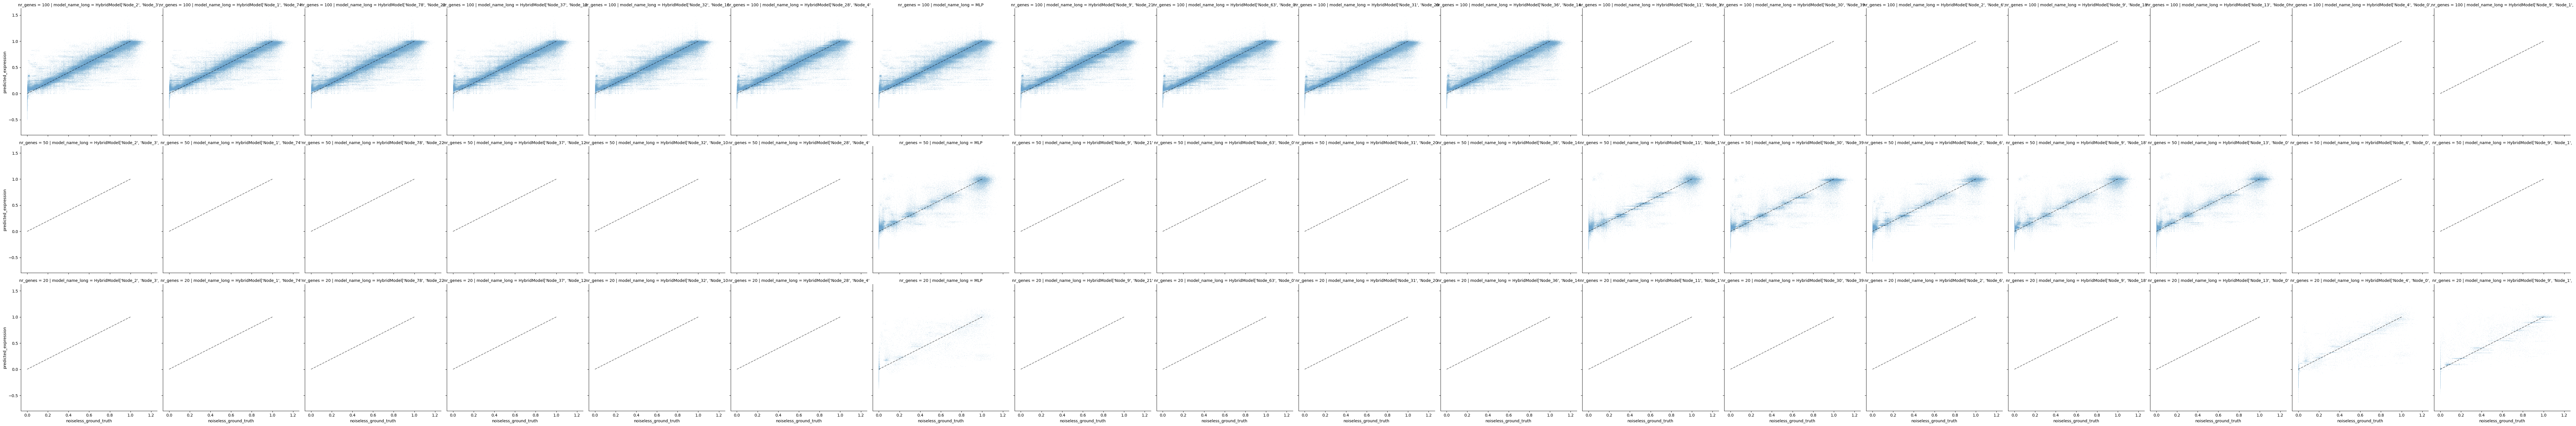

In [43]:
g =sns.relplot(data=double_ko_df, kind='scatter', x='noiseless_ground_truth', y='predicted_expression', col='model_name_long', row='nr_genes', s=2, alpha=.2, marker='.')

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)

# Plotting for double KO

In [93]:
from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import re

robust_cmap = True
norm_function = Normalize
cmap = "viridis"

groupby_list = [
    'model_name',
    'modelled_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'nr_genes'
]
mse_df = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

mlp_mse = mse_df[mse_df['model_name'] == 'MLP'][['gene', 'condition', 'nr_genes', 'MSE']].rename(columns={'MSE': 'mlp_mse'})
hybrid_mse = mse_df[mse_df['model_name'] == 'HybridModel'][['gene', 'condition', 'nr_genes', 'MSE', 'modelled_genes']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mlp_mse, on=['gene', 'condition', 'nr_genes'])


def make_ko_lookup(df):
    unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
    lookup = {}
    for _, row in unique_combos.iterrows():
        cond = row['condition']
        genes = row['modelled_genes']
        kos = re.findall(r"Node_\d+", cond)
        
        if all(f"'{ko}'" in genes for ko in kos):
            ko_in_modelled_genes = 'fully'
        elif any(f"'{ko}'" in genes for ko in kos):
            ko_in_modelled_genes = 'partially'
        else:
            ko_in_modelled_genes = 'none'
        
        key = (cond, genes)
        lookup[key] = ko_in_modelled_genes
    
    return lookup

lookup = make_ko_lookup(paired)
paired['gene_ko_in_mechanistic_model'] = paired.apply(
    lambda row: lookup[(
        row['condition'],
        row['modelled_genes'] if row['modelled_genes'] is not None else None
    )],
    axis=1
)


In [99]:
paired.head()

,gene,condition,nr_genes,hybrid_mse,modelled_genes,mlp_mse,gene_ko_in_mechanistic_model
0,Node_0,"KO: Node_0, Node_19. Env: None",100,0.030686,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.029936,none
1,Node_0,"KO: Node_0, Node_2. Env: None",100,0.031205,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.029662,none
2,Node_0,"KO: Node_0, Node_23. Env: None",100,0.023840,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.023259,none
3,Node_0,"KO: Node_0, Node_24. Env: None",100,0.022217,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.021572,none
4,Node_0,"KO: Node_0, Node_3. Env: None",100,0.026834,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.025545,none


In [105]:
paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)

In [108]:
paired[['gene_ko_in_mechanistic_model', 'gene_in_mm']].value_counts()

gene_ko_in_mechanistic_model  gene_in_mm
none                          False         87634
                              True          10696
fully                         False          9213
partially                     False          3553
fully                         True           1617
partially                     True            587
Name: count, dtype: int64

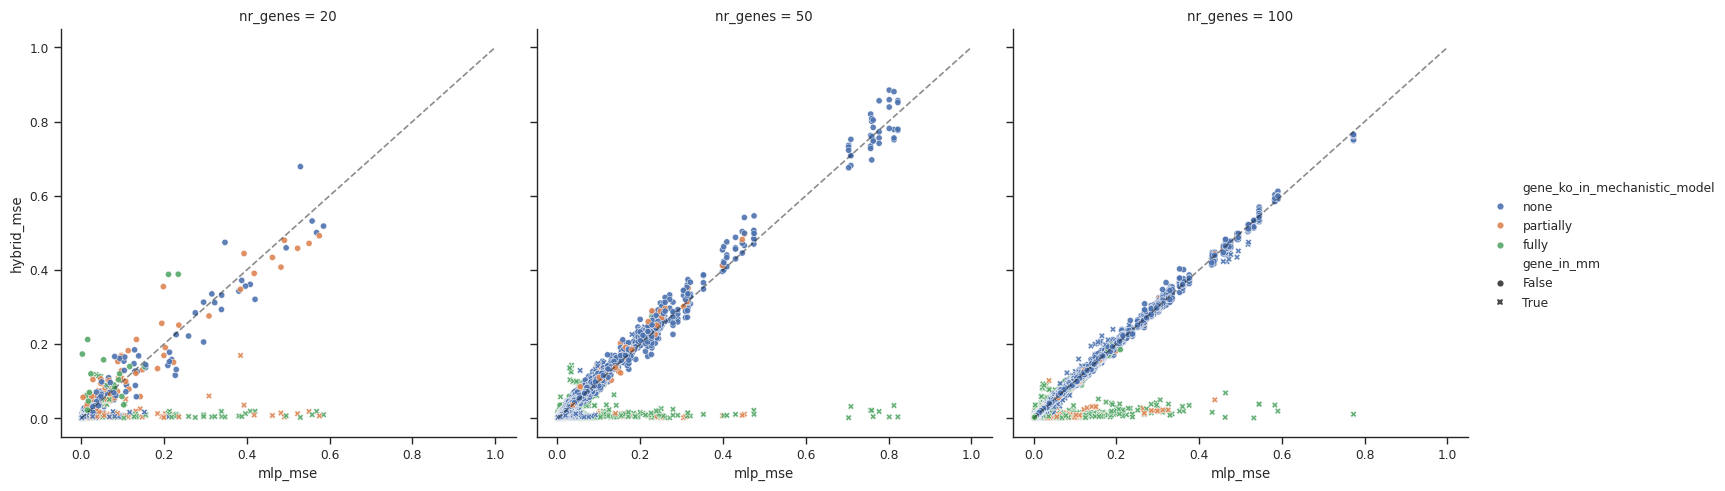

In [116]:
sns.set_context("paper")
sns.set_style('ticks')
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', hue='gene_ko_in_mechanistic_model', col='nr_genes', style='gene_in_mm', alpha=.9, s=20, col_order=natsorted(paired['nr_genes'].unique()))
# g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)


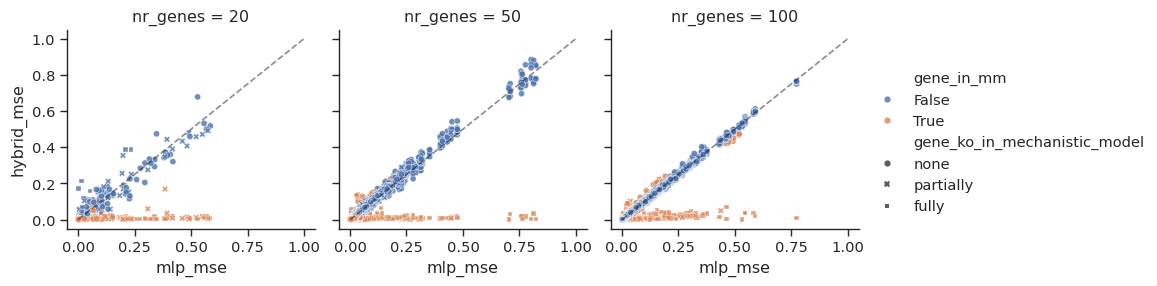

In [ ]:
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='nr_genes', hue='gene_in_mm', style='gene_ko_in_mechanistic_model',  alpha=.8, s=20, col_order=natsorted(paired['nr_genes'].unique()), height=3, aspect=1)
# g.figure.set_size_inches(9, 3) 
# g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
# plt.tight_layout()
g.savefig("mm_size_comparison.pdf", dpi=600, bbox_inches='tight', )